Starting PINN Training...
Epoch 0, Loss: 0.39332
Epoch 1000, Loss: 0.02222
Epoch 2000, Loss: 0.00724
Epoch 3000, Loss: 0.00430
Epoch 4000, Loss: 0.00406

Generating exact numerical solution for benchmarking...
Benchmark Complete! Relative L2 Error: 6.88807e-02


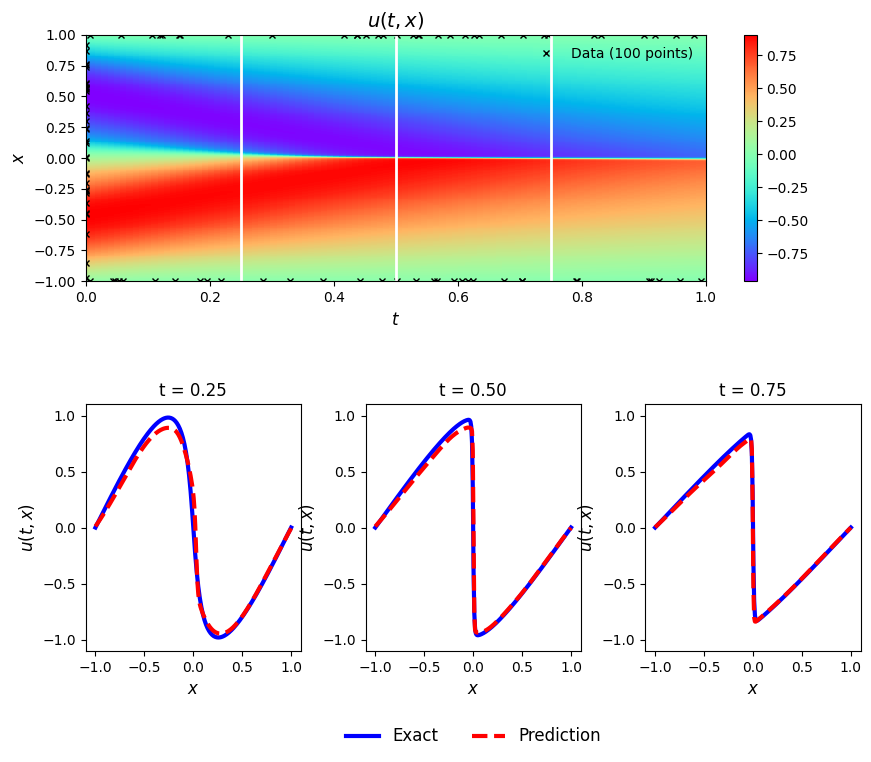

In [9]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import scipy.io
from scipy.integrate import solve_ivp
import matplotlib.gridspec as gridspec

# Random seed for reproducibility
torch.manual_seed(1234)
np.random.seed(1234)

# ==========================================
# 1. PINN Model Architecture
# ==========================================
class PINN(nn.Module):
    def __init__(self, layers):
        super(PINN, self).__init__()
        self.hidden_layers = nn.ModuleList()
        for i in range(len(layers) - 2):
            self.hidden_layers.append(nn.Linear(layers[i], layers[i+1]))
        self.output_layer = nn.Linear(layers[-2], layers[-1])

        # Paper uses Tanh activation function
        self.activation = nn.Tanh()

    def forward(self, x, t):
        inputs = torch.cat([x, t], dim=1)
        layer_output = inputs
        for layer in self.hidden_layers:
            layer_output = self.activation(layer(layer_output))
        u = self.output_layer(layer_output)
        return u

# ==========================================
# 2. Physics-Informed Loss (PDE Residual)
# ==========================================
def compute_physics_loss(model, x_f, t_f):
    x_f.requires_grad = True
    t_f.requires_grad = True

    u = model(x_f, t_f)

    u_x = torch.autograd.grad(u, x_f, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_t = torch.autograd.grad(u, t_f, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_xx = torch.autograd.grad(u_x, x_f, grad_outputs=torch.ones_like(u_x), create_graph=True)[0]

    # Burgers' Equation
    f = u_t + u * u_x - (0.01 / np.pi) * u_xx
    loss_f = torch.mean(f ** 2)
    return loss_f

# ==========================================
# 3. Data Generation (Initial & Boundary)
# ==========================================
def generate_training_data(N_u, N_f):
    x_ic = np.random.uniform(-1, 1, (N_u // 3, 1))
    t_ic = np.zeros((N_u // 3, 1))
    u_ic = -np.sin(np.pi * x_ic)

    t_bc1 = np.random.uniform(0, 1, (N_u // 3, 1))
    x_bc1 = -np.ones((N_u // 3, 1))
    u_bc1 = np.zeros((N_u // 3, 1))

    t_bc2 = np.random.uniform(0, 1, (N_u // 3 + (N_u % 3), 1))
    x_bc2 = np.ones((len(t_bc2), 1))
    u_bc2 = np.zeros((len(t_bc2), 1))

    x_u = np.vstack([x_ic, x_bc1, x_bc2])
    t_u = np.vstack([t_ic, t_bc1, t_bc2])
    u_train = np.vstack([u_ic, u_bc1, u_bc2])

    x_f = np.random.uniform(-1, 1, (N_f, 1))
    t_f = np.random.uniform(0, 1, (N_f, 1))

    x_u_tensor = torch.tensor(x_u, dtype=torch.float32)
    t_u_tensor = torch.tensor(t_u, dtype=torch.float32)
    u_tensor = torch.tensor(u_train, dtype=torch.float32)
    x_f_tensor = torch.tensor(x_f, dtype=torch.float32)
    t_f_tensor = torch.tensor(t_f, dtype=torch.float32)

    return x_u_tensor, t_u_tensor, u_tensor, x_f_tensor, t_f_tensor

# ==========================================
# 4. Training Loop
# ==========================================
layers = [2, 20, 20, 20, 20, 20, 20, 20, 20, 1]
model = PINN(layers)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

N_u = 100
N_f = 10000
x_u, t_u, u_train, x_f, t_f = generate_training_data(N_u, N_f)

epochs = 5000
print("Starting PINN Training...")
for epoch in range(epochs):
    optimizer.zero_grad()

    u_pred = model(x_u, t_u)
    loss_u = torch.mean((u_pred - u_train) ** 2)
    loss_f = compute_physics_loss(model, x_f, t_f)

    loss = loss_u + loss_f
    loss.backward()
    optimizer.step()

    if epoch % 1000 == 0:
        print(f'Epoch {epoch}, Loss: {loss.item():.5f}')

# ==========================================
# 5. EXACT NUMERICAL SOLUTION (BASELINE) - FIXED
# ==========================================
print("\nGenerating exact numerical solution for benchmarking...")
nx = 256
dx = 2.0 / (nx - 1)
nu = 0.01 / np.pi

def burgers_rhs(t, u):
    du_dx = np.zeros_like(u)
    # FIX: Applied Upwind scheme to prevent solver crash at the shockwave
    du_dx[1:-1] = np.where(u[1:-1] > 0,
                           (u[1:-1] - u[:-2]) / dx,
                           (u[2:] - u[1:-1]) / dx)

    du_dxx = np.zeros_like(u)
    du_dxx[1:-1] = (u[2:] - 2 * u[1:-1] + u[:-2]) / (dx**2)

    du_dt = -u * du_dx + nu * du_dxx
    du_dt[0] = 0
    du_dt[-1] = 0
    return du_dt

t_flat = np.linspace(0, 1, 100)
x_flat = np.linspace(-1, 1, 256)
T, X = np.meshgrid(t_flat, x_flat)

X_test = torch.tensor(X.flatten()[:, None], dtype=torch.float32)
T_test = torch.tensor(T.flatten()[:, None], dtype=torch.float32)

with torch.no_grad():
    u_pred_test = model(X_test, T_test).numpy()
    U_pred = u_pred_test.reshape(X.shape)

u0 = -np.sin(np.pi * x_flat)

# FIX: Switched to LSODA method and removed strict tolerances for robust integration
sol = solve_ivp(burgers_rhs, [0, 1], u0, t_eval=t_flat, method='LSODA')

Exact_U = sol.y

# Dimensions will now perfectly match as (256, 100)
error_u = np.linalg.norm(Exact_U - U_pred, 2) / np.linalg.norm(Exact_U, 2)
print(f"Benchmark Complete! Relative L2 Error: {error_u:.5e}")

# ==========================================
# 6. EXACT PAPER-STYLE PLOTTING (FIGURE A.6)
# ==========================================
fig = plt.figure(figsize=(10, 8))
gs = gridspec.GridSpec(2, 3, height_ratios=[1, 1])
gs.update(hspace=0.5, wspace=0.3)

# --- Top Panel: Heatmap with Data Points ---
ax0 = fig.add_subplot(gs[0, :])
c = ax0.pcolormesh(T, X, U_pred, cmap='rainbow', shading='auto')
fig.colorbar(c, ax=ax0)

# Plot training data points
ax0.plot(t_u.numpy(), x_u.numpy(), 'kx', markersize=5, label='Data (100 points)')

# Plot white vertical lines
ax0.axvline(x=0.25, color='w', linestyle='-', linewidth=2)
ax0.axvline(x=0.50, color='w', linestyle='-', linewidth=2)
ax0.axvline(x=0.75, color='w', linestyle='-', linewidth=2)

ax0.set_xlabel('$t$', fontsize=12)
ax0.set_ylabel('$x$', fontsize=12)
ax0.set_title('$u(t,x)$', fontsize=14)
ax0.set_xlim([0, 1])
ax0.set_ylim([-1, 1])
ax0.legend(loc='upper right', frameon=False, fontsize=10)

# --- Bottom Panels: 1D Slices ---
time_steps = [25, 50, 75] # indices for t = 0.25, 0.50, 0.75
titles = ['t = 0.25', 't = 0.50', 't = 0.75']

for i, t_idx in enumerate(time_steps):
    ax = fig.add_subplot(gs[1, i])
    # FIX 2: Slicing changed to [:, t_idx] because time is now the second dimension (columns)
    ax.plot(x_flat, Exact_U[:, t_idx], 'b-', linewidth=3, label='Exact')
    ax.plot(x_flat, U_pred[:, t_idx], 'r--', linewidth=3, label='Prediction')

    ax.set_xlabel('$x$', fontsize=12)
    ax.set_ylabel('$u(t,x)$', fontsize=12)
    ax.set_title(titles[i], fontsize=12)
    ax.set_xlim([-1.1, 1.1])
    ax.set_ylim([-1.1, 1.1])

    if i == 1:
        ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.25), ncol=2, frameon=False, fontsize=12)

plt.show()

In [8]:
# ==========================================
# 5. EXACT NUMERICAL SOLUTION (BASELINE) - FIXED
# ==========================================
print("\nGenerating exact numerical solution for benchmarking...")
nx = 256
dx = 2.0 / (nx - 1)
nu = 0.01 / np.pi

def burgers_rhs(t, u):
    du_dx = np.zeros_like(u)
    # FIX: Applied Upwind scheme to prevent solver crash at the shockwave
    du_dx[1:-1] = np.where(u[1:-1] > 0,
                           (u[1:-1] - u[:-2]) / dx,
                           (u[2:] - u[1:-1]) / dx)

    du_dxx = np.zeros_like(u)
    du_dxx[1:-1] = (u[2:] - 2 * u[1:-1] + u[:-2]) / (dx**2)

    du_dt = -u * du_dx + nu * du_dxx
    du_dt[0] = 0
    du_dt[-1] = 0
    return du_dt

t_flat = np.linspace(0, 1, 100)
x_flat = np.linspace(-1, 1, 256)
T, X = np.meshgrid(t_flat, x_flat)

X_test = torch.tensor(X.flatten()[:, None], dtype=torch.float32)
T_test = torch.tensor(T.flatten()[:, None], dtype=torch.float32)

with torch.no_grad():
    u_pred_test = model(X_test, T_test).numpy()
    U_pred = u_pred_test.reshape(X.shape)

u0 = -np.sin(np.pi * x_flat)

# FIX: Switched to LSODA method and removed strict tolerances for robust integration
sol = solve_ivp(burgers_rhs, [0, 1], u0, t_eval=t_flat, method='LSODA')

Exact_U = sol.y

# Dimensions will now perfectly match as (256, 100)
error_u = np.linalg.norm(Exact_U - U_pred, 2) / np.linalg.norm(Exact_U, 2)
print(f"Benchmark Complete! Relative L2 Error: {error_u:.5e}")


Generating exact numerical solution for benchmarking...
Benchmark Complete! Relative L2 Error: 6.88807e-02


Phase 1: Adam Optimizer Warmup...
Adam Epoch 0, Total Loss: 3.93321e-01
Adam Epoch 500, Total Loss: 4.52545e-02
Adam Epoch 1000, Total Loss: 2.27929e-02
Adam Epoch 1500, Total Loss: 1.10619e-02

Phase 2: L-BFGS Optimizer (High Precision)...
L-BFGS Complete, Final Total Loss: 4.29243e-06

Generating exact numerical solution for benchmarking...
Benchmark Complete! Relative L2 Error: 2.65489e-02


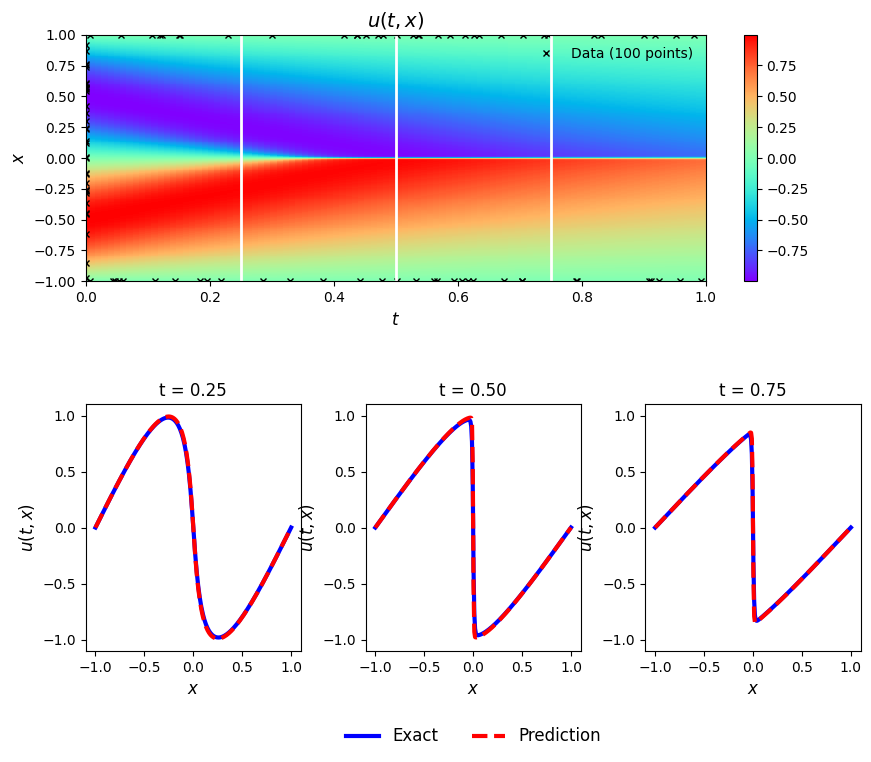

In [10]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import matplotlib.gridspec as gridspec
from scipy.stats import qmc

# Random seed for reproducibility
torch.manual_seed(1234)
np.random.seed(1234)

# ==========================================
# 1. PINN Model Architecture
# ==========================================
class PINN(nn.Module):
    def __init__(self, layers):
        super(PINN, self).__init__()
        self.hidden_layers = nn.ModuleList()
        for i in range(len(layers) - 2):
            self.hidden_layers.append(nn.Linear(layers[i], layers[i+1]))
        self.output_layer = nn.Linear(layers[-2], layers[-1])

        # Paper uses Tanh activation function
        self.activation = nn.Tanh()

    def forward(self, x, t):
        inputs = torch.cat([x, t], dim=1)
        layer_output = inputs
        for layer in self.hidden_layers:
            layer_output = self.activation(layer(layer_output))
        u = self.output_layer(layer_output)
        return u

# ==========================================
# 2. Physics-Informed Loss (PDE Residual)
# ==========================================
def compute_physics_loss(model, x_f, t_f):
    x_f.requires_grad = True
    t_f.requires_grad = True

    u = model(x_f, t_f)

    u_x = torch.autograd.grad(u, x_f, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_t = torch.autograd.grad(u, t_f, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_xx = torch.autograd.grad(u_x, x_f, grad_outputs=torch.ones_like(u_x), create_graph=True)[0]

    # Burgers' Equation
    f = u_t + u * u_x - (0.01 / np.pi) * u_xx
    loss_f = torch.mean(f ** 2)
    return loss_f

# ==========================================
# 3. Data Generation (LHS + Initial/Boundary)
# ==========================================
def generate_training_data(N_u, N_f):
    # Latin Hypercube Sampling for Collocation Points
    sampler = qmc.LatinHypercube(d=2, seed=1234)
    sample = sampler.random(n=N_f)

    x_f = -1 + 2 * sample[:, 0:1]
    t_f = sample[:, 1:2]

    # Initial Condition: t = 0
    x_ic = np.random.uniform(-1, 1, (N_u // 3, 1))
    t_ic = np.zeros((N_u // 3, 1))
    u_ic = -np.sin(np.pi * x_ic)

    # Boundary Conditions
    t_bc1 = np.random.uniform(0, 1, (N_u // 3, 1))
    x_bc1 = -np.ones((N_u // 3, 1))
    u_bc1 = np.zeros((N_u // 3, 1))

    t_bc2 = np.random.uniform(0, 1, (N_u // 3 + (N_u % 3), 1))
    x_bc2 = np.ones((len(t_bc2), 1))
    u_bc2 = np.zeros((len(t_bc2), 1))

    x_u = np.vstack([x_ic, x_bc1, x_bc2])
    t_u = np.vstack([t_ic, t_bc1, t_bc2])
    u_train = np.vstack([u_ic, u_bc1, u_bc2])

    x_u_tensor = torch.tensor(x_u, dtype=torch.float32)
    t_u_tensor = torch.tensor(t_u, dtype=torch.float32)
    u_tensor = torch.tensor(u_train, dtype=torch.float32)
    x_f_tensor = torch.tensor(x_f, dtype=torch.float32)
    t_f_tensor = torch.tensor(t_f, dtype=torch.float32)

    return x_u_tensor, t_u_tensor, u_tensor, x_f_tensor, t_f_tensor

# ==========================================
# 4. Training Loop (Adam + L-BFGS)
# ==========================================
layers = [2, 20, 20, 20, 20, 20, 20, 20, 20, 1]
model = PINN(layers)

N_u = 100
N_f = 10000
x_u, t_u, u_train, x_f, t_f = generate_training_data(N_u, N_f)

print("Phase 1: Adam Optimizer Warmup...")
optimizer_adam = torch.optim.Adam(model.parameters(), lr=1e-3)
for epoch in range(2000):
    optimizer_adam.zero_grad()
    u_pred = model(x_u, t_u)
    loss_u = torch.mean((u_pred - u_train) ** 2)
    loss_f = compute_physics_loss(model, x_f, t_f)
    loss = loss_u + loss_f
    loss.backward()
    optimizer_adam.step()
    if epoch % 500 == 0:
        print(f'Adam Epoch {epoch}, Total Loss: {loss.item():.5e}')

print("\nPhase 2: L-BFGS Optimizer (High Precision)...")
optimizer_lbfgs = torch.optim.LBFGS(
    model.parameters(), lr=1.0, max_iter=50000, max_eval=50000,
    history_size=50, tolerance_grad=1e-5,
    tolerance_change=1.0 * np.finfo(float).eps, line_search_fn="strong_wolfe"
)

def closure():
    optimizer_lbfgs.zero_grad()
    u_pred = model(x_u, t_u)
    loss_u = torch.mean((u_pred - u_train) ** 2)
    loss_f = compute_physics_loss(model, x_f, t_f)
    loss = loss_u + loss_f
    loss.backward()
    return loss

optimizer_lbfgs.step(closure)
final_loss = closure()
print(f'L-BFGS Complete, Final Total Loss: {final_loss.item():.5e}')

# ==========================================
# 5. EXACT NUMERICAL SOLUTION (BASELINE)
# ==========================================
print("\nGenerating exact numerical solution for benchmarking...")
nx = 256
dx = 2.0 / (nx - 1)
nu = 0.01 / np.pi

def burgers_rhs(t, u):
    du_dx = np.zeros_like(u)
    du_dx[1:-1] = np.where(u[1:-1] > 0,
                           (u[1:-1] - u[:-2]) / dx,
                           (u[2:] - u[1:-1]) / dx)
    du_dxx = np.zeros_like(u)
    du_dxx[1:-1] = (u[2:] - 2 * u[1:-1] + u[:-2]) / (dx**2)

    du_dt = -u * du_dx + nu * du_dxx
    du_dt[0] = 0
    du_dt[-1] = 0
    return du_dt

t_flat = np.linspace(0, 1, 100)
x_flat = np.linspace(-1, 1, 256)
T, X = np.meshgrid(t_flat, x_flat)

X_test = torch.tensor(X.flatten()[:, None], dtype=torch.float32)
T_test = torch.tensor(T.flatten()[:, None], dtype=torch.float32)

with torch.no_grad():
    u_pred_test = model(X_test, T_test).numpy()
    U_pred = u_pred_test.reshape(X.shape)

u0 = -np.sin(np.pi * x_flat)
sol = solve_ivp(burgers_rhs, [0, 1], u0, t_eval=t_flat, method='LSODA')
Exact_U = sol.y

error_u = np.linalg.norm(Exact_U - U_pred, 2) / np.linalg.norm(Exact_U, 2)
print(f"Benchmark Complete! Relative L2 Error: {error_u:.5e}")

# ==========================================
# 6. EXACT PAPER-STYLE PLOTTING (FIGURE A.6)
# ==========================================
fig = plt.figure(figsize=(10, 8))
gs = gridspec.GridSpec(2, 3, height_ratios=[1, 1])
gs.update(hspace=0.5, wspace=0.3)

# --- Top Panel: Heatmap ---
ax0 = fig.add_subplot(gs[0, :])
c = ax0.pcolormesh(T, X, U_pred, cmap='rainbow', shading='auto')
fig.colorbar(c, ax=ax0)

ax0.plot(t_u.numpy(), x_u.numpy(), 'kx', markersize=5, label='Data (100 points)')
ax0.axvline(x=0.25, color='w', linestyle='-', linewidth=2)
ax0.axvline(x=0.50, color='w', linestyle='-', linewidth=2)
ax0.axvline(x=0.75, color='w', linestyle='-', linewidth=2)

ax0.set_xlabel('$t$', fontsize=12)
ax0.set_ylabel('$x$', fontsize=12)
ax0.set_title('$u(t,x)$', fontsize=14)
ax0.set_xlim([0, 1])
ax0.set_ylim([-1, 1])
ax0.legend(loc='upper right', frameon=False, fontsize=10)

# --- Bottom Panels: 1D Slices ---
time_steps = [25, 50, 75]
titles = ['t = 0.25', 't = 0.50', 't = 0.75']

for i, t_idx in enumerate(time_steps):
    ax = fig.add_subplot(gs[1, i])
    ax.plot(x_flat, Exact_U[:, t_idx], 'b-', linewidth=3, label='Exact')
    ax.plot(x_flat, U_pred[:, t_idx], 'r--', linewidth=3, label='Prediction')

    ax.set_xlabel('$x$', fontsize=12)
    ax.set_ylabel('$u(t,x)$', fontsize=12)
    ax.set_title(titles[i], fontsize=12)
    ax.set_xlim([-1.1, 1.1])
    ax.set_ylim([-1.1, 1.1])

    if i == 1:
        ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.25), ncol=2, frameon=False, fontsize=12)

plt.show()

Phase 1: Adam Optimizer Warmup...
Adam Epoch 0, Total Loss: 3.93321e-01
Adam Epoch 500, Total Loss: 4.52545e-02
Adam Epoch 1000, Total Loss: 2.27929e-02
Adam Epoch 1500, Total Loss: 1.10619e-02

Phase 2: L-BFGS Optimizer (High Precision)...
L-BFGS Complete, Final Total Loss: 4.29243e-06

Loading exact analytical solution for benchmarking...
Benchmark Complete! Relative L2 Error: 1.11454e-03


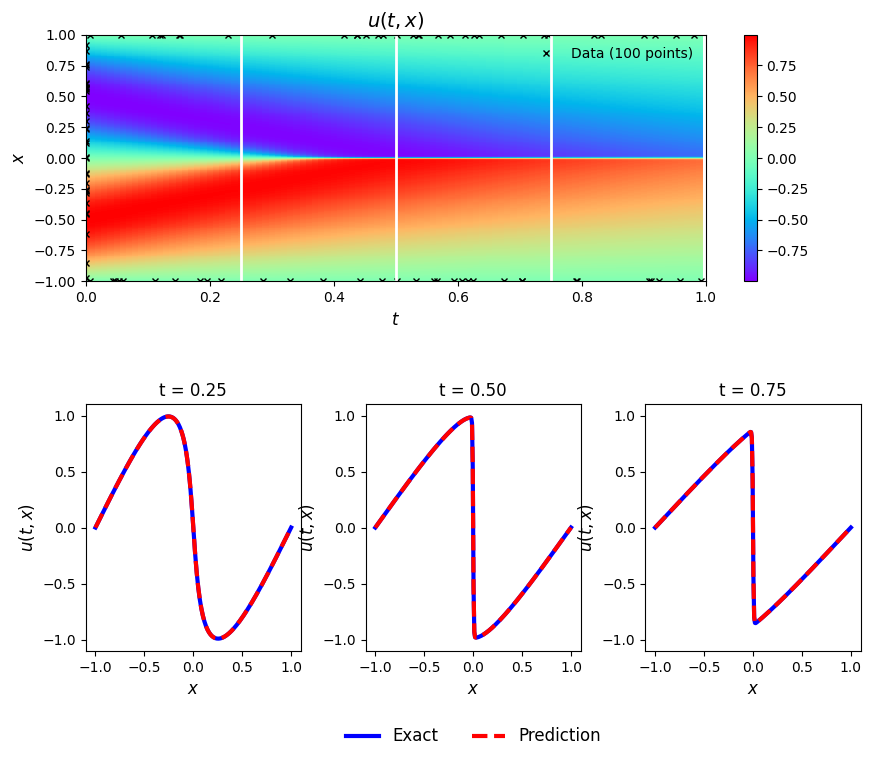

In [2]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import scipy.io
import matplotlib.gridspec as gridspec
from scipy.stats import qmc

# Random seed for reproducibility
torch.manual_seed(1234)
np.random.seed(1234)

# ==========================================
# 1. PINN Model Architecture
# ==========================================
class PINN(nn.Module):
    def __init__(self, layers):
        super(PINN, self).__init__()
        self.hidden_layers = nn.ModuleList()
        for i in range(len(layers) - 2):
            self.hidden_layers.append(nn.Linear(layers[i], layers[i+1]))
        self.output_layer = nn.Linear(layers[-2], layers[-1])

        self.activation = nn.Tanh()

    def forward(self, x, t):
        inputs = torch.cat([x, t], dim=1)
        layer_output = inputs
        for layer in self.hidden_layers:
            layer_output = self.activation(layer(layer_output))
        u = self.output_layer(layer_output)
        return u

# ==========================================
# 2. Physics-Informed Loss (PDE Residual)
# ==========================================
def compute_physics_loss(model, x_f, t_f):
    x_f.requires_grad = True
    t_f.requires_grad = True

    u = model(x_f, t_f)

    u_x = torch.autograd.grad(u, x_f, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_t = torch.autograd.grad(u, t_f, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_xx = torch.autograd.grad(u_x, x_f, grad_outputs=torch.ones_like(u_x), create_graph=True)[0]

    f = u_t + u * u_x - (0.01 / np.pi) * u_xx
    loss_f = torch.mean(f ** 2)
    return loss_f

# ==========================================
# 3. Data Generation (LHS + Initial/Boundary)
# ==========================================
def generate_training_data(N_u, N_f):
    sampler = qmc.LatinHypercube(d=2, seed=1234)
    sample = sampler.random(n=N_f)

    x_f = -1 + 2 * sample[:, 0:1]
    t_f = sample[:, 1:2]

    x_ic = np.random.uniform(-1, 1, (N_u // 3, 1))
    t_ic = np.zeros((N_u // 3, 1))
    u_ic = -np.sin(np.pi * x_ic)

    t_bc1 = np.random.uniform(0, 1, (N_u // 3, 1))
    x_bc1 = -np.ones((N_u // 3, 1))
    u_bc1 = np.zeros((N_u // 3, 1))

    t_bc2 = np.random.uniform(0, 1, (N_u // 3 + (N_u % 3), 1))
    x_bc2 = np.ones((len(t_bc2), 1))
    u_bc2 = np.zeros((len(t_bc2), 1))

    x_u = np.vstack([x_ic, x_bc1, x_bc2])
    t_u = np.vstack([t_ic, t_bc1, t_bc2])
    u_train = np.vstack([u_ic, u_bc1, u_bc2])

    x_u_tensor = torch.tensor(x_u, dtype=torch.float32)
    t_u_tensor = torch.tensor(t_u, dtype=torch.float32)
    u_tensor = torch.tensor(u_train, dtype=torch.float32)
    x_f_tensor = torch.tensor(x_f, dtype=torch.float32)
    t_f_tensor = torch.tensor(t_f, dtype=torch.float32)

    return x_u_tensor, t_u_tensor, u_tensor, x_f_tensor, t_f_tensor

# ==========================================
# 4. Training Loop (Adam + L-BFGS)
# ==========================================
layers = [2, 20, 20, 20, 20, 20, 20, 20, 20, 1]
model = PINN(layers)

N_u = 100
N_f = 10000
x_u, t_u, u_train, x_f, t_f = generate_training_data(N_u, N_f)

print("Phase 1: Adam Optimizer Warmup...")
optimizer_adam = torch.optim.Adam(model.parameters(), lr=1e-3)
for epoch in range(2000):
    optimizer_adam.zero_grad()
    u_pred = model(x_u, t_u)
    loss_u = torch.mean((u_pred - u_train) ** 2)
    loss_f = compute_physics_loss(model, x_f, t_f)
    loss = loss_u + loss_f
    loss.backward()
    optimizer_adam.step()
    if epoch % 500 == 0:
        print(f'Adam Epoch {epoch}, Total Loss: {loss.item():.5e}')

print("\nPhase 2: L-BFGS Optimizer (High Precision)...")
optimizer_lbfgs = torch.optim.LBFGS(
    model.parameters(), lr=1.0, max_iter=50000, max_eval=50000,
    history_size=50, tolerance_grad=1e-5,
    tolerance_change=1.0 * np.finfo(float).eps, line_search_fn="strong_wolfe"
)

def closure():
    optimizer_lbfgs.zero_grad()
    u_pred = model(x_u, t_u)
    loss_u = torch.mean((u_pred - u_train) ** 2)
    loss_f = compute_physics_loss(model, x_f, t_f)
    loss = loss_u + loss_f
    loss.backward()
    return loss

optimizer_lbfgs.step(closure)
final_loss = closure()
print(f'L-BFGS Complete, Final Total Loss: {final_loss.item():.5e}')

# ==========================================
# 5. EXACT ANALYTICAL SOLUTION (PAPER'S DATASET)
# ==========================================
print("\nLoading exact analytical solution for benchmarking...")

try:
    data = scipy.io.loadmat('burgers_shock.mat')

    t_flat = np.real(data['t']).flatten()
    x_flat = np.real(data['x']).flatten()
    Exact_U = np.real(data['usol'])
    T, X = np.meshgrid(t_flat, x_flat)

    X_test = torch.tensor(X.flatten()[:, None], dtype=torch.float32)
    T_test = torch.tensor(T.flatten()[:, None], dtype=torch.float32)

    with torch.no_grad():
        u_pred_test = model(X_test, T_test).numpy()
        U_pred = u_pred_test.reshape(X.shape)

    error_u = np.linalg.norm(Exact_U - U_pred, 2) / np.linalg.norm(Exact_U, 2)
    print(f"Benchmark Complete! Relative L2 Error: {error_u:.5e}")

except FileNotFoundError:
    print("Error: 'burgers_shock.mat' file not found. Make sure it's in the same folder.")

# ==========================================
# 6. EXACT PAPER-STYLE PLOTTING (FIGURE A.6)
# ==========================================
if 'U_pred' in locals():
    fig = plt.figure(figsize=(10, 8))
    gs = gridspec.GridSpec(2, 3, height_ratios=[1, 1])
    gs.update(hspace=0.5, wspace=0.3)

    # --- Top Panel: Heatmap ---
    ax0 = fig.add_subplot(gs[0, :])
    c = ax0.pcolormesh(T, X, U_pred, cmap='rainbow', shading='auto')
    fig.colorbar(c, ax=ax0)

    ax0.plot(t_u.numpy(), x_u.numpy(), 'kx', markersize=5, label='Data (100 points)')
    ax0.axvline(x=0.25, color='w', linestyle='-', linewidth=2)
    ax0.axvline(x=0.50, color='w', linestyle='-', linewidth=2)
    ax0.axvline(x=0.75, color='w', linestyle='-', linewidth=2)

    ax0.set_xlabel('$t$', fontsize=12)
    ax0.set_ylabel('$x$', fontsize=12)
    ax0.set_title('$u(t,x)$', fontsize=14)
    ax0.set_xlim([0, 1])
    ax0.set_ylim([-1, 1])
    ax0.legend(loc='upper right', frameon=False, fontsize=10)

    # --- Bottom Panels: 1D Slices ---
    # Find closest indices for t = 0.25, 0.50, 0.75 in the official dataset
    idx_25 = np.argmin(np.abs(t_flat - 0.25))
    idx_50 = np.argmin(np.abs(t_flat - 0.50))
    idx_75 = np.argmin(np.abs(t_flat - 0.75))

    time_steps = [idx_25, idx_50, idx_75]
    titles = ['t = 0.25', 't = 0.50', 't = 0.75']

    for i, t_idx in enumerate(time_steps):
        ax = fig.add_subplot(gs[1, i])
        ax.plot(x_flat, Exact_U[:, t_idx], 'b-', linewidth=3, label='Exact')
        ax.plot(x_flat, U_pred[:, t_idx], 'r--', linewidth=3, label='Prediction')

        ax.set_xlabel('$x$', fontsize=12)
        ax.set_ylabel('$u(t,x)$', fontsize=12)
        ax.set_title(titles[i], fontsize=12)
        ax.set_xlim([-1.1, 1.1])
        ax.set_ylim([-1.1, 1.1])

        if i == 1:
            ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.25), ncol=2, frameon=False, fontsize=12)

    plt.show()